In [1]:
# Uncomment when importing from GitHub
# !git clone https://www.github.com/simoneroncallo/quantum-optical-neuron.git
# %cd /content/quantum-optical-neuron
# !mkdir ./output/data

# Uncomment when importing from Google Drive
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/'Colab Notebooks'/quantum-optical-neuron-main

Mounted at /content/drive
/content/drive/MyDrive/Colab Notebooks/quantum-optical-neuron-main


In [2]:
import sys

# Uncomment when importing from GitHub
# dir = '/content/quantum-optical-neuron'

# Uncomment when importing from Google Drive
dir = '/content/drive/MyDrive/"Colab Notebooks"/quantum-optical-neuron-main'

sys.path.append(dir)
from qon import spatial_loss_derivative, Fourier_loss_derivative
from qon import optimization

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from keras import layers, models, activations, optimizers
from keras.datasets import cifar10
from keras.utils import set_random_seed

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/tmp/ipython-input-3-1688903375.py", line 3, in <cell line: 0>
    from keras import layers, models, activations, optimizers
  File "<frozen importlib._bootstrap>", line 1176, in _find_and_load
  File "<frozen importlib._bootstrap>", line 1138, in _find_and_load_unlocked
  File "<frozen importlib._bootstrap>", line 1078, in _find_spec
  File "<frozen importlib._bootstrap_external>", line 1507, in find_spec
  File "<frozen importlib._bootstrap_external>", line 1476, in _get_spec
  File "<frozen importlib._bootstrap_external>", line 1434, in _path_importer_cache
OSError: [Errno 107] Transport endpoint is not connected

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/IPython/core/interac

In [ ]:
def rgb2gray(rgb):
  """ Convert an RGB digital image to greyscale. """
  return np.dot(rgb[...,:3], [0.2989, 0.5870, 0.1140])

In [ ]:
# Set the seeds
np.random.seed(2024)
set_random_seed(2024)

In [ ]:
# Hyperparameters
numEpochs = 300
learningRateWeights = 0.075
learningRateBias = 0.005
numTrainImgs = None # Load the full dataset with "None"
numShots = -1 # Deactivate noise with "-1"

# Dataset
We use the CIFAR-10 dataset, which contains $32 \times 32$ color images, distributed across $10$ different classes. We guaranteed a fair comparison by converting each image to greyscale. We train the models to distinguish among images of *cats* and *dogs*.

After normalization, each element of the dataset is identified with the corrisponding amplitudes of quantum optical neuron input state, bypassing the simulation of the imaging apparatus.

In [ ]:
# Load the CIFAR dataset
(trainImgs, trainLabels), (testImgs, testLabels) = cifar10.load_data()

# Filter dogs and planes from the the dataset
trainCats, testCats = np.where(trainLabels == 3), np.where(testLabels == 3)
trainDogs, testDogs = np.where(trainLabels == 5), np.where(testLabels == 5)

trainCatImgs = trainImgs[trainCats[0]]
trainDogImgs = trainImgs[trainDogs[0]]

testCatImgs = testImgs[testCats[0]]
testDogImgs = testImgs[testDogs[0]]

trainImgs = np.concatenate((trainCatImgs, trainDogImgs), axis = 0)
testImgs = np.concatenate((testCatImgs, testDogImgs), axis = 0)

# Assign 0 to cats and 1 to dogs
trainCatLabels = np.zeros(trainCatImgs.shape[0])
trainDogLabels = np.ones(trainDogImgs.shape[0])
trainLabels = np.concatenate((trainCatLabels, trainDogLabels), axis = 0)

testCatLabels = np.zeros(testCatImgs.shape[0])
testDogLabels = np.ones(testDogImgs.shape[0])
testLabels = np.concatenate((testCatLabels, testDogLabels), axis = 0)

# Reshuffle images and labels consistently
idxs = np.arange(trainImgs.shape[0])
np.random.shuffle(idxs)

trainImgs = trainImgs[idxs]
trainLabels = trainLabels[idxs]

# Convert to float
trainImgs = trainImgs.astype(np.float64)
testImgs = testImgs.astype(np.float64)
trainLabels = trainLabels.astype(np.float64)
testLabels = testLabels.astype(np.float64)

# Identify each image with the single-photon discretized amplitudes
for idx, trainImg in enumerate(trainImgs):
  trainImg = rgb2gray(trainImg)
  trainImgs[idx,:,:,0] = trainImg/np.sum(trainImg) # Normalization
for idx, testImg in enumerate(testImgs):
  testImg = rgb2gray(testImgs[idx,:,:,:])
  testImgs[idx,:,:,0] = testImg/np.sum(testImg) # Normalization

# Amplitudes
trainImgs = np.sqrt(trainImgs[:,:,:,0])
testImgs = np.sqrt(testImgs[:,:,:,0])

# Reduce the training set
trainImgs = trainImgs[:numTrainImgs,:,:]
trainLabels = trainLabels[:numTrainImgs]

print('Training set has shape', trainImgs.shape)

Training set has shape (10000, 32, 32)


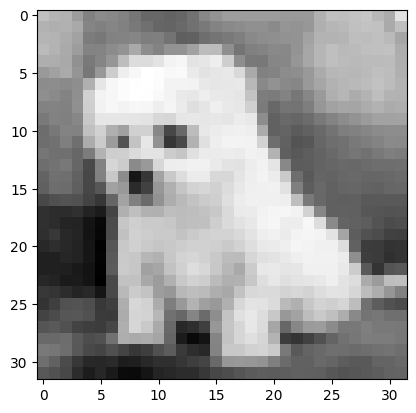

In [ ]:
# Print example
idx = 10
plt.imshow(np.square(trainImgs[idx,:,:]))
plt.gray()
plt.show()

# <font color='ORANGE'>Simulation</font>
 We numerically compare the predictability of the quantum optical neuron against that of conventional neural network designs, constrained to the same number of parameters.

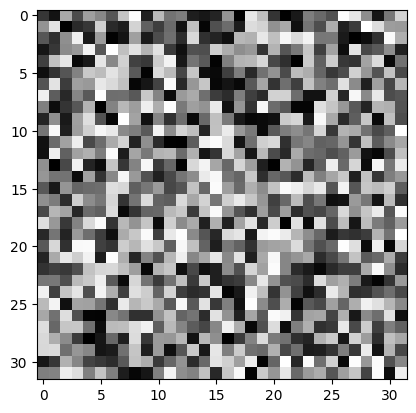

In [ ]:
# Parameters random initialization
initial_weights = np.random.uniform(-1,1,(32,32)) # Uniform sampling
bias = 0

# Normalization
norm = np.sum(np.square(initial_weights))
weights = initial_weights/np.sqrt(norm)

plt.imshow(weights[:,:])
plt.gray()

In [ ]:
# Training
weights, bias, loss_history, test_loss_history, accuracy_history,\
              test_accuracy_history = optimization(spatial_loss_derivative,\
                weights, bias, trainLabels, testLabels, trainImgs, testImgs,\
                  numEpochs, learningRateWeights, learningRateBias, numShots)

EPOCH 0
Loss 2.7533901826630784 Val_Loss 2.7533170507398217
Accuracy 0.5 Val_Acc 0.5
---
EPOCH 1
Loss 2.604381203772493 Val_Loss 2.6042654341017712
Accuracy 0.5 Val_Acc 0.5
---
EPOCH 2
Loss 2.4554336870173263 Val_Loss 2.4552419964973966
Accuracy 0.5 Val_Acc 0.5
---
EPOCH 3
Loss 2.3050970060605076 Val_Loss 2.304769239978158
Accuracy 0.5 Val_Acc 0.5
---
EPOCH 4
Loss 2.148495619208813 Val_Loss 2.147921650621408
Accuracy 0.5 Val_Acc 0.5
---
EPOCH 5
Loss 1.9707205057310884 Val_Loss 1.969696696622877
Accuracy 0.5 Val_Acc 0.5
---
EPOCH 6
Loss 1.7302986378481078 Val_Loss 1.7284582682233482
Accuracy 0.5 Val_Acc 0.5
---
EPOCH 7
Loss 1.3377316124315213 Val_Loss 1.3345664612234938
Accuracy 0.5 Val_Acc 0.5
---
EPOCH 8
Loss 0.8052751971409413 Val_Loss 0.801476322199567
Accuracy 0.5 Val_Acc 0.5
---
EPOCH 9
Loss 0.7117135158887077 Val_Loss 0.7100343920352439
Accuracy 0.5109 Val_Acc 0.52
---
EPOCH 10
Loss 0.7019888922585085 Val_Loss 0.6990863779464502
Accuracy 0.501 Val_Acc 0.501
---
EPOCH 11
Loss 0.69

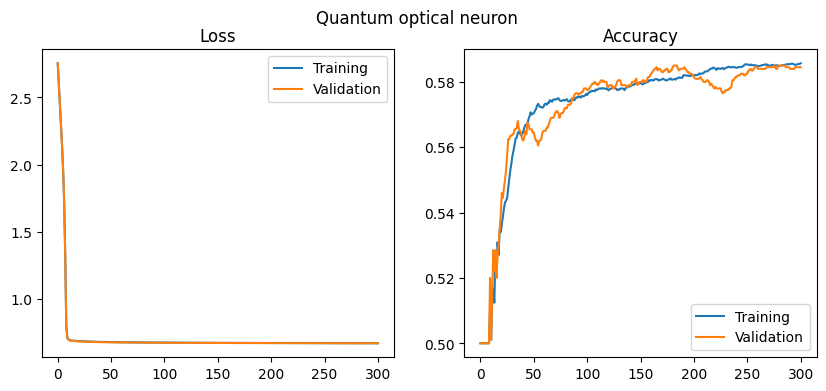

In [ ]:
# History plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(loss_history, label = 'Training')
ax1.plot(test_loss_history, label = 'Validation')

ax1.set_title('Loss')
ax1.legend()

ax2.plot(accuracy_history, label = 'Training')
ax2.plot(test_accuracy_history, label = 'Validation')

ax2.set_title('Accuracy')
ax2.legend()

fig.suptitle('Quantum optical neuron')
plt.show()

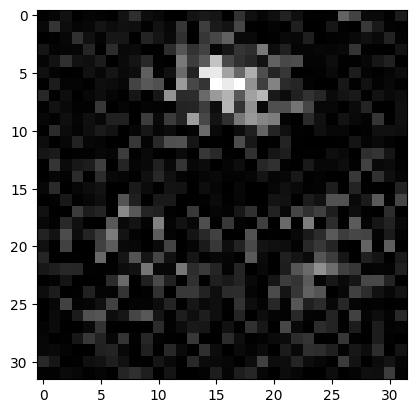

In [ ]:
# Parameters plot
# Normalization
norm = np.sum(np.square(weights))
weights = weights/np.sqrt(norm)

probWeights = np.square(weights)

plt.imshow(probWeights)
plt.gray()

plt.show()

### Single neuron

In [ ]:
model = models.Sequential()

model.add(layers.Flatten(input_shape=(32, 32, 1)))
model.add(layers.Dense(1, activation='sigmoid', use_bias=True))

model.build()
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,025 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,025 (4.00 KB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
optimizer = optimizers.SGD(learning_rate = learningRateWeights)
model.compile(optimizer=optimizer, loss='binary_crossentropy', \
              metrics=['accuracy'])
dense_history = model.fit(trainImgs, trainLabels, \
                    batch_size = trainImgs.shape[0], \
                    epochs = numEpochs,
                    validation_data=(testImgs, testLabels))

Epoch 1/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step - accuracy: 0.5174 - loss: 0.6930 - val_accuracy: 0.5065 - val_loss: 0.6931
Epoch 2/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.5168 - loss: 0.6929 - val_accuracy: 0.5045 - val_loss: 0.6931
Epoch 3/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 375ms/step - accuracy: 0.5174 - loss: 0.6929 - val_accuracy: 0.5035 - val_loss: 0.6931
Epoch 4/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 517ms/step - accuracy: 0.5181 - loss: 0.6929 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 5/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 260ms/step - accuracy: 0.5185 - loss: 0.6929 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 6/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 305ms/step - accuracy: 0.5176 - loss: 0.6929 - val_accuracy: 0.5015 - val_loss: 0.6931
Epoch 7/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step - accuracy: 0.5178 - loss: 0.6929 - val_accuracy: 0.5010 - val_loss: 0.6931
Epoch 8/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 379ms/step - accuracy: 0.5171 - loss: 0.6929 - val_accuracy: 0.5020 - val_los

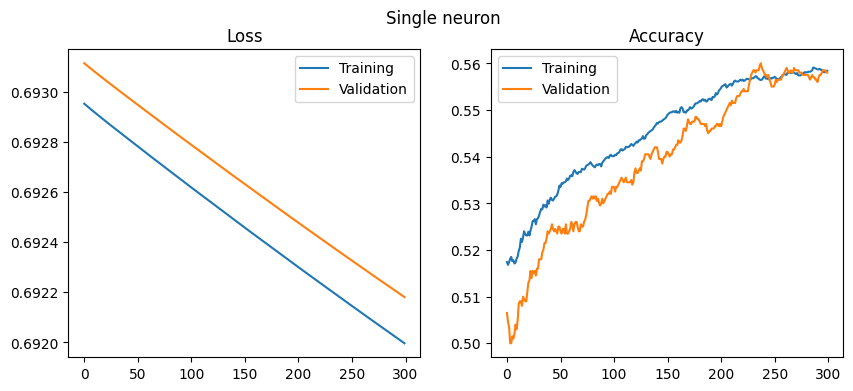

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(dense_history.history['loss'], label = 'Training')
ax1.plot(dense_history.history['val_loss'], label = 'Validation')

ax1.set_title('Loss')
ax1.legend()

ax2.plot(dense_history.history['accuracy'], label = 'Training')
ax2.plot(dense_history.history['val_accuracy'], label = 'Validation')

ax2.set_title('Accuracy')
ax2.legend()

fig.suptitle('Single neuron')
plt.show()

### Convolutional network

In [ ]:
model = models.Sequential()

model.add(layers.Conv2D(10, (3, 3), activation='linear', use_bias=False, \
                        input_shape=(32, 32, 1)))
model.add(layers.Conv2D(4, (2, 2), activation='linear', use_bias=False))
model.add(layers.MaxPooling2D((2, 2)))

model.add(layers.Flatten())
model.add(layers.Dense(1, activation='sigmoid', use_bias=True))

model.build()
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 10)     │            90 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 4)      │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           785 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,035 (4.04 KB)

 Trainable params: 1,035 (4.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
optimizer = optimizers.SGD(learning_rate = learningRateWeights)
model.compile(optimizer=optimizer, loss='binary_crossentropy', \
              metrics=['accuracy'])
conv_history = model.fit(trainImgs, trainLabels, \
                    batch_size = trainImgs.shape[0], \
                    epochs = numEpochs,
                    validation_data=(testImgs, testLabels))

Epoch 1/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step - accuracy: 0.5010 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 2/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - accuracy: 0.5012 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 3/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 0.5011 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 4/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - accuracy: 0.5008 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6930
Epoch 5/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step - accuracy: 0.5009 - loss: 0.6931 - val_accuracy: 0.4995 - val_loss: 0.6930
Epoch 6/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - accuracy: 0.5009 - loss: 0.6931 - val_accuracy: 0.4995 - val_loss: 0.6930
Epoch 7/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - accuracy: 0.5009 - loss: 0.6931 - val_accuracy: 0.4995 - val_loss: 0.6930
Epoch 8/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step - accuracy: 0.5010 - loss: 0.6930 - val_accuracy: 0.4985 - val_

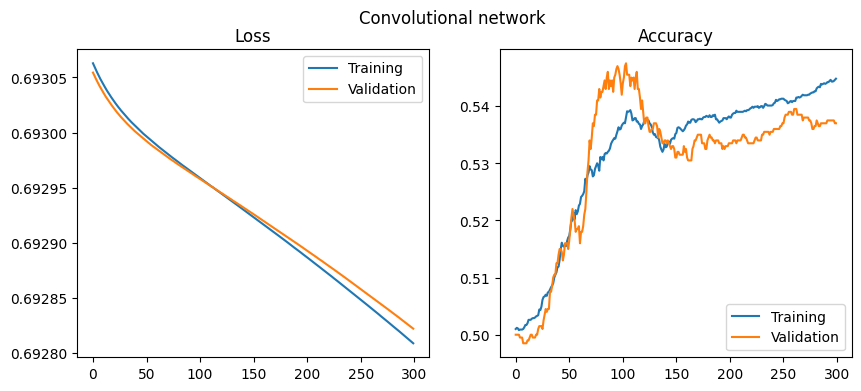

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(conv_history.history['loss'], label = 'Training')
ax1.plot(conv_history.history['val_loss'], label = 'Validation')

ax1.set_title('Loss')
ax1.legend()

ax2.plot(conv_history.history['accuracy'], label = 'Training')
ax2.plot(conv_history.history['val_accuracy'], label = 'Validation')

ax2.set_title('Accuracy')
ax2.legend()

fig.suptitle('Convolutional network')
plt.show()

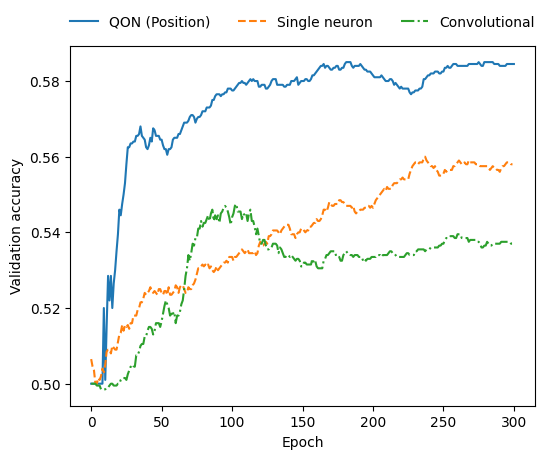

In [ ]:
fig, ax1 = plt.subplots(figsize=(6, 5.5))

# Main plot
ax1.plot(test_accuracy_history, linestyle = '-', \
         label = 'QON (Position)')

ax1.plot(dense_history.history['val_accuracy'], linestyle = '--', \
         label = 'Single neuron')

ax1.plot(conv_history.history['val_accuracy'], linestyle = '-.', \
         label = 'Convolutional')

ax1.set_xlabel('Epoch')
ax1.set_ylabel('Validation accuracy')

pos = ax1.get_position()
ax1.set_position([pos.x0, pos.y0, pos.width, pos.height * 0.85])
ax1.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, 1.12),
    ncol=3,
    frameon=False,
)

plt.show()

In [ ]:
# Quantum optical neuron history
np.save('output/data/CIFARposition_OQPloss.npy', test_loss_history)
np.save('output/data/CIFARposition_OQPacc.npy', test_accuracy_history)

# Single neuron history
np.save('output/data/CIFARposition_MLPloss.npy', \
          np.array(dense_history.history['val_loss']))
np.save('output/data/CIFARposition_MLPacc.npy', \
          np.array(dense_history.history['val_accuracy']))

# Convolutional network history
np.save('output/data/CIFARposition_CONVloss.npy', \
          np.array(conv_history.history['val_loss']))
np.save('output/data/CIFARposition_CONVacc.npy', \
          np.array(conv_history.history['val_accuracy']))

# <font color='ORANGE'>Simulation</font> (Fourier encoding)
We repeat the same analysis and comparisons by encoding the dataset in the Fourier domain.

In [ ]:
# Reinitialize the Tensorflow seed
set_random_seed(2024)

In [ ]:
# Compute the fast Fourier transform
trainFourierImgs = np.zeros(trainImgs.shape, dtype = np.complex64)
testFourierImgs = np.zeros(testImgs.shape, dtype = np.complex64)

for idx, trainImg in enumerate(trainImgs):
  trainFourierImgs[idx,:,:] = np.transpose(np.fft.fftshift(\
                          np.fft.fft2(trainImgs[idx,:,:], norm = "ortho")))
  if idx < testImgs.shape[0]:
    testFourierImgs[idx,:,:] = np.transpose(np.fft.fftshift(\
                          np.fft.fft2(testImgs[idx,:,:],  norm = "ortho")))

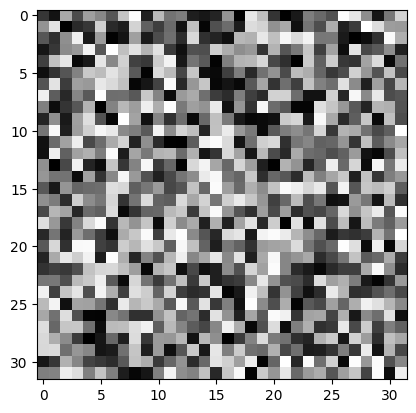

In [ ]:
# Parameters reinizialization and normalization
bias = 0
norm = np.sum(np.square(initial_weights))
weights = initial_weights/np.sqrt(norm)

plt.imshow(weights[:,:])
plt.gray()

In [ ]:
# Training
weights, bias, loss_history, test_loss_history, accuracy_history,\
        test_accuracy_history = optimization(Fourier_loss_derivative, weights,\
          bias, trainLabels, testLabels, trainFourierImgs, testFourierImgs,\
            numEpochs, learningRateWeights, learningRateBias, numShots)

EPOCH 0
Loss 2.748417090876182 Val_Loss 2.7483597369925477
Accuracy 0.5 Val_Acc 0.5
---
EPOCH 1
Loss 2.588359267658986 Val_Loss 2.588224653635396
Accuracy 0.5 Val_Acc 0.5
---
EPOCH 2
Loss 2.405669456102377 Val_Loss 2.405369140195376
Accuracy 0.5 Val_Acc 0.5
---
EPOCH 3
Loss 2.1549432467787795 Val_Loss 2.15426893955268
Accuracy 0.5 Val_Acc 0.5
---
EPOCH 4
Loss 1.7223616651942273 Val_Loss 1.7208544957718017
Accuracy 0.5 Val_Acc 0.5
---
EPOCH 5
Loss 0.994103782718782 Val_Loss 0.9913787268854867
Accuracy 0.5 Val_Acc 0.5
---
EPOCH 6
Loss 0.7248617299172708 Val_Loss 0.7237614867301949
Accuracy 0.51 Val_Acc 0.516
---
EPOCH 7
Loss 0.7126521683494278 Val_Loss 0.7103912701027997
Accuracy 0.5 Val_Acc 0.5
---
EPOCH 8
Loss 0.7032918747360077 Val_Loss 0.7018259663084593
Accuracy 0.514 Val_Acc 0.5165
---
EPOCH 9
Loss 0.6989690222010592 Val_Loss 0.6969272115153146
Accuracy 0.5031 Val_Acc 0.5035
---
EPOCH 10
Loss 0.6958048791861716 Val_Loss 0.6941832070329579
Accuracy 0.5144 Val_Acc 0.5175
---
EPOCH 11

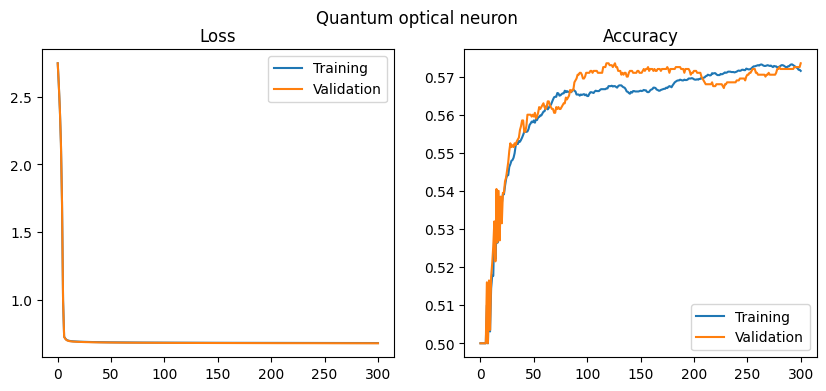

In [ ]:
# History plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(loss_history, label = 'Training')
ax1.plot(test_loss_history, label = 'Validation')

ax1.set_title('Loss')
ax1.legend()

ax2.plot(accuracy_history, label = 'Training')
ax2.plot(test_accuracy_history, label = 'Validation')

ax2.set_title('Accuracy')
ax2.legend()

fig.suptitle('Quantum optical neuron')
plt.show()

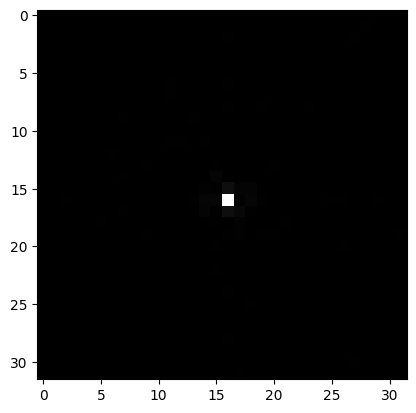

In [ ]:
# Parameters plot
# Normalization
norm = np.sum(np.square(weights))
weights = weights/np.sqrt(norm)

probWeights = np.square(weights)

plt.imshow(probWeights)
plt.gray()

plt.show()

### Single neuron

In [ ]:
model = models.Sequential()

model.add(layers.Flatten(input_shape=(32, 32, 1)))
model.add(layers.Dense(1, activation='sigmoid', use_bias=True))

model.build()
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         1,025 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,025 (4.00 KB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
optimizer = optimizers.SGD(learning_rate = learningRateWeights)
model.compile(optimizer=optimizer, loss='binary_crossentropy', \
              metrics=['accuracy'])
dense_history = model.fit(np.abs(trainFourierImgs), trainLabels, \
                    batch_size = trainImgs.shape[0], \
                    epochs = numEpochs,
                    validation_data=(np.abs(testFourierImgs), testLabels))

Epoch 1/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 830ms/step - accuracy: 0.5000 - loss: 0.6936 - val_accuracy: 0.5000 - val_loss: 0.6935
Epoch 2/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step - accuracy: 0.5000 - loss: 0.6936 - val_accuracy: 0.5000 - val_loss: 0.6935
Epoch 3/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - accuracy: 0.5000 - loss: 0.6935 - val_accuracy: 0.5000 - val_loss: 0.6935
Epoch 4/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step - accuracy: 0.5000 - loss: 0.6935 - val_accuracy: 0.5000 - val_loss: 0.6935
Epoch 5/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.5000 - loss: 0.6935 - val_accuracy: 0.5000 - val_loss: 0.6935
Epoch 6/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.5000 - loss: 0.6935 - val_accuracy: 0.5000 - val_loss: 0.6934
Epoch 7/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 0.5000 - loss: 0.6935 - val_accuracy: 0.5000 - val_loss: 0.6934
Epoch 8/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step - accuracy: 0.5000 - loss: 0.6934 - val_accuracy: 0.5000 - v

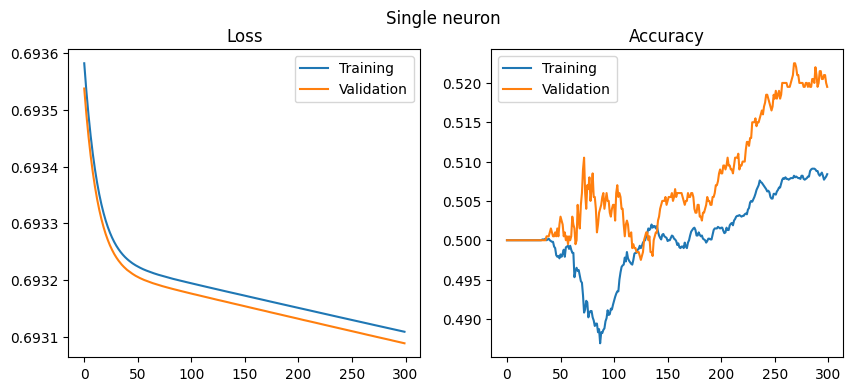

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(dense_history.history['loss'], label = 'Training')
ax1.plot(dense_history.history['val_loss'], label = 'Validation')

ax1.set_title('Loss')
ax1.legend()

ax2.plot(dense_history.history['accuracy'], label = 'Training')
ax2.plot(dense_history.history['val_accuracy'], label = 'Validation')

ax2.set_title('Accuracy')
ax2.legend()

fig.suptitle('Single neuron')
plt.show()

### Convolutional network

In [ ]:
model = models.Sequential()

model.add(layers.Conv2D(10, (3, 3), activation='linear', use_bias=False, \
                        input_shape=(32, 32, 1)))
model.add(layers.Conv2D(4, (2, 2), activation='linear', use_bias=False))
model.add(layers.MaxPooling2D((2, 2)))

model.add(layers.Flatten())
model.add(layers.Dense(1, activation='sigmoid', use_bias=True))

model.build()
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 30, 30, 10)     │            90 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 29, 29, 4)      │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           785 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,035 (4.04 KB)

 Trainable params: 1,035 (4.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
optimizer = optimizers.SGD(learning_rate = learningRateWeights)
model.compile(optimizer=optimizer, loss='binary_crossentropy', \
              metrics=['accuracy'])
conv_history = model.fit(np.abs(trainFourierImgs), trainLabels, \
                    batch_size = trainImgs.shape[0], \
                    epochs = numEpochs,
                    validation_data=(np.abs(testFourierImgs), testLabels))

Epoch 1/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.5000 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 2/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 304ms/step - accuracy: 0.5000 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 3/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 325ms/step - accuracy: 0.5000 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 4/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 264ms/step - accuracy: 0.5000 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 5/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 291ms/step - accuracy: 0.5000 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 6/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step - accuracy: 0.5000 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 7/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 300ms/step - accuracy: 0.5000 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 8/300
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 211ms/step - accuracy: 0.5000 - loss: 0.6931 - val_accuracy: 0.5000 - val_

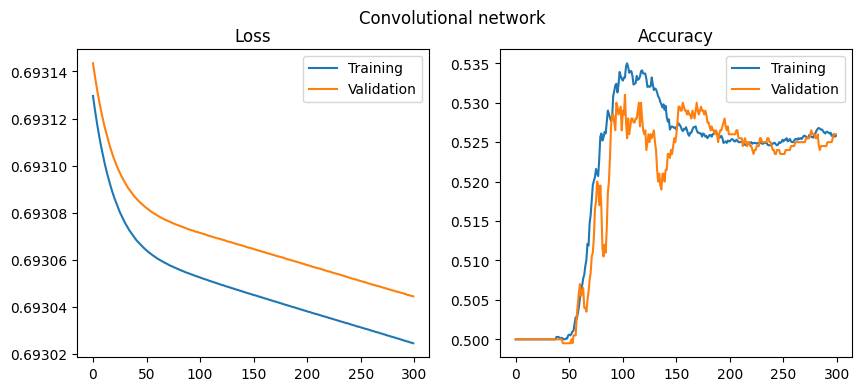

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(conv_history.history['loss'], label = 'Training')
ax1.plot(conv_history.history['val_loss'], label = 'Validation')

ax1.set_title('Loss')
ax1.legend()

ax2.plot(conv_history.history['accuracy'], label = 'Training')
ax2.plot(conv_history.history['val_accuracy'], label = 'Validation')

ax2.set_title('Accuracy')
ax2.legend()

fig.suptitle('Convolutional network')
plt.show()

## Comparison

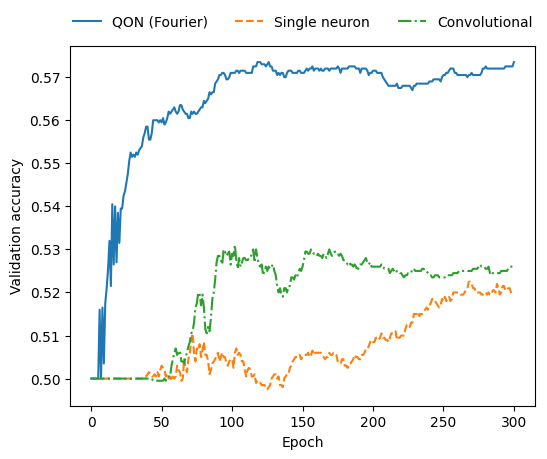

In [ ]:
fig, ax1 = plt.subplots(figsize=(6, 5.5))

# Main plot
ax1.plot(test_accuracy_history, linestyle = '-', \
         label = 'QON (Fourier)')

ax1.plot(dense_history.history['val_accuracy'], linestyle = '--', \
         label = 'Single neuron')

ax1.plot(conv_history.history['val_accuracy'], linestyle = '-.', \
         label = 'Convolutional')

ax1.set_xlabel('Epoch')
ax1.set_ylabel('Validation accuracy')

pos = ax1.get_position()
ax1.set_position([pos.x0, pos.y0, pos.width, pos.height * 0.85])
ax1.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, 1.12),
    ncol=3,
    frameon=False,
)

plt.show()

In [ ]:
# Quantum optical neuron history
np.save('output/data/CIFARfourier_OQPloss.npy', test_loss_history)
np.save('output/data/CIFARfourier_OQPacc.npy', test_accuracy_history)

# Single neuron history
np.save('output/data/CIFARfourier_MLPloss.npy', \
          np.array(dense_history.history['val_loss']))
np.save('output/data/CIFARfourier_MLPacc.npy', \
          np.array(dense_history.history['val_accuracy']))

# Convolutional network history
np.save('output/data/CIFARfourier_CONVloss.npy', \
          np.array(conv_history.history['val_loss']))
np.save('output/data/CIFARfourier_CONVacc.npy', \
          np.array(conv_history.history['val_accuracy']))